# UTS Graf Sains Data

| Mata Kuliah | Graf Sains Data |
| :--- | :--- |
| Nama | Muhammad Ariq Hibatullah |
| NIM | 23031554064 |
| Kelas | 2023A |

Notebook ini mendokumentasikan soal, penjelasan, serta jawaban. Isi notebook ini terdiri dari:
1. Tugas Pendahuluan
2. Soal UTS
   - Wrangling dan EDA
   - Analytics
3. Kesimpulan

## SETUP DAN PARAMETER

Library yang digunakan

In [21]:
import os
import pandas as pd
from neo4j import GraphDatabase, RoutingControl
from tqdm.auto import tqdm
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import scipy.sparse as sp

c:\Users\lenovo\Documents\graf-data\myvenv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Koneksi ke Database

In [40]:
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin1234")
DATABASE = "uts"

driver = GraphDatabase.driver(URI, auth=AUTH)
print("Terhubung ke", URI, ", database UTS:", DATABASE)


Terhubung ke neo4j://localhost:7687 , database UTS: uts


Parameter

In [56]:
# Import data
FILE_PATH = "data_filtered/events_p1.csv"
BATCH_SIZE = 5000

# Path file event.csv
df_retailrocket = pd.read_csv("data/events.csv")
df_retailrocket["datetime"] = pd.to_datetime(df_retailrocket["timestamp"], unit="ms")

# Rentang data
p1_start = "2015-05-15"
p1_end   = "2015-07-03"

p2_start = "2015-07-04"
p2_end   = "2015-07-17"

# KNN
k = 5
SEED = 42

## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan
Pada bagian ini diperintahkan untuk membuat virtual environment baru dan menginstall dependensi paket-paket yang diperlukan. Perintah yang dijalankan:
```text
uv venv myvenv --python 3.10
conda deactivate
myvenv\Scripts\activate
uv pip install -r requirements.txt
```

Seluruh paket sudah berhasil di install, tetapi ada penyesuaian pada versi neo4j karena jika menggunakan versi 4.2.1 ada terdapat error, jadi saya menggunakan versi terbarunya.

In [4]:
import importlib.metadata

packages = ["neo4j", "imdbpy", "nose", "cinemagoerng", "imdbinfo"]

for pkg in packages:
    try:
        version = importlib.metadata.version(pkg)
        print(f"✅ {pkg}: Terinstal (Versi {version})")
    except importlib.metadata.PackageNotFoundError:
        print(f"❌ {pkg}: Belum terinstal")

✅ neo4j: Terinstal (Versi 6.4.1)
✅ imdbpy: Terinstal (Versi 2020.9.25)
✅ nose: Terinstal (Versi 1.3.7)
✅ cinemagoerng: Terinstal (Versi 0.4)
✅ imdbinfo: Terinstal (Versi 0.11.0)


### 1.2 Mempelajari Penggunaan Driver Neo4J

Menggunakan database "neo4j" agar tidak mempengaruhi pengerjaan soal UTS nanti.

In [5]:
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "admin1234")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


#### Pertanyaan Pendahuluan

**1. Apa nama database yang digunakan pada tutorial ini?**<br>
Pada tutorial ini saya menggunakan database bernama "neo4j" yang bisa dilihat pada variabel AUTH.
```text
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "pass")
```

**2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**<br>
| Mekanisme | Contoh sintaks |
| :--- | :--- |
| Klause | USE uts MATCH (i:Item) RETURN count(i) |
| Sintaks Administrasi DDL via Database | USE system SHOW DATABASES, CREATE DATABASE, ALTER DATABASE |
| Driver Session | driver.session(database="uts") |
| cypher-shell | :use uts |

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**<br>
Graf tersebut merupakan **Directed Graph** karena relasi `MERGE (a)-[:KNOWS]->(friend)` memiliki tanda panah yang menunjukkan bahwa hubungan `KNOWS` hanya mengalir satu arah dari simpul asal ke simpul tujuan.

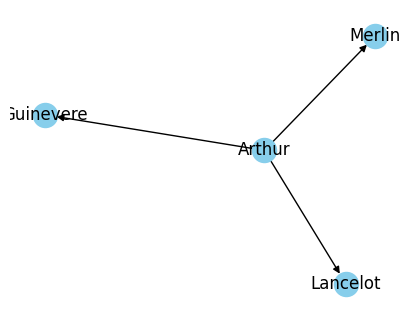

In [6]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name, b.name"
    )

G = nx.DiGraph([(r["a.name"], r["b.name"]) for r in records])
plt.figure(figsize=(4, 3))
nx.draw(G, with_labels=True, node_color="skyblue", arrows=True)
plt.show()

#### CYPHER Total Reset
Pada bagian ini diperintahkan untuk melakukan penghapusan konten pada database. Perintah yang dijalankan:
```text
MATCH (n) DETACH DELETE n;
```

In [7]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    res_before, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total", database_="neo4j"
    )
    print("Jumlah node sebelum:", res_before[0]["total"])

    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")

    res_after, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total", database_="neo4j"
    )
    print("Jumlah node sesudah:", res_after[0]["total"])

Jumlah node sebelum: 4
Jumlah node sesudah: 0


### 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J
Pada bagian ini diperintahkan untuk mengunduh data RetailRocket padaq Kaggle dari Roman Zykov. Perintah yang dijalankan:
```text
curl.exe -L -o ecommerce-dataset.zip '
    https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```

Hasil unduhan berupa file `ecommerce-dataset.zip`, yang dimana isinya dipindahkan ke dalam folder `data/`.

In [10]:
isi_folder = os.listdir("./data")
print(isi_folder)

['category_tree.csv', 'events.csv', 'item_properties_part1.csv', 'item_properties_part2.csv']


File events.csv memiliki fitur sebagai berikut:
1. timestamp: Waktu dalam format unix epoch.
2. visitorid: ID unik pengunjung.
3. event: Jenis interaksi default: view, addtocart, transaction.
4. itemid: ID unik produk.
5. transactionid: ID transaksi, hanya terisi saat event berjenis 'transaction'.

tetapi untuk data ini memiliki ketimpangan data yang sangat besar pada data 'event'-nya, yaitu terdapat `view` sebesar 96.7%, `addtocard` sebesar 2.5%, dan `transaction` sebesar 0.8%.

In [15]:
df_retailrocket.info()

jumlah = df_retailrocket["event"].value_counts()
persen = df_retailrocket["event"].value_counts(normalize=True) * 100
tabel_distribusi = pd.DataFrame({"Nilai Unik": jumlah.index, "Jumlah": jumlah.values, "Persentase (%)": persen.values})
print("")
print(tabel_distribusi)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 6 columns):
 #   Column         Dtype         
---  ------         -----         
 0   timestamp      int64         
 1   visitorid      int64         
 2   event          object        
 3   itemid         int64         
 4   transactionid  float64       
 5   datetime       datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 126.2+ MB

    Nilai Unik   Jumlah  Persentase (%)
0         view  2664312       96.669607
1    addtocart    69332        2.515583
2  transaction    22457        0.814810


Setelah itu dilanjutkan juga dengan membuat sistem import data csv ke dalam database neo4j

In [22]:
with driver.session(database=DATABASE) as session:
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )
print("Constraint berhasil dibuat/dipastikan ada.")

cypher_query = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL {
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
"""

Constraint berhasil dibuat/dipastikan ada.


## 2. Soal UTS  |  2.1 Wrangling dan EDA

### 2.1.1 Tentukan 2 periode waktu sebagai filter dari data interaksi.
Dataset tersebut memiliki rentang data dengan timestamp 03/5/2015 - 18/9/2015. Saya tidak ingin mengambil data pada rentang terakhir (sekitar tanggal 15/9/2025 ke atas) karena terdapat penurunan nilai drastis hingga mendekati 0. Pada Grafik terlihat bahwa pola naik turunnya data konsisten pada tiap minggunya.

Jadi saya akan memilih datanya dengan satuan per minggu. Data yang akan saya gunakan adalah:
- P1 -> `15/5/2025` - `3/7/2025` (6 Minggu)
- P2 -> `4/7/2025` - `17/7/2025` (2 Minggu)

Tanggal Awal   : 2015-05-03 03:00:04.384000
Tanggal Akhir  : 2015-09-18 02:59:47.788000
Total Durasi   : 137 days 23:59:43.404000


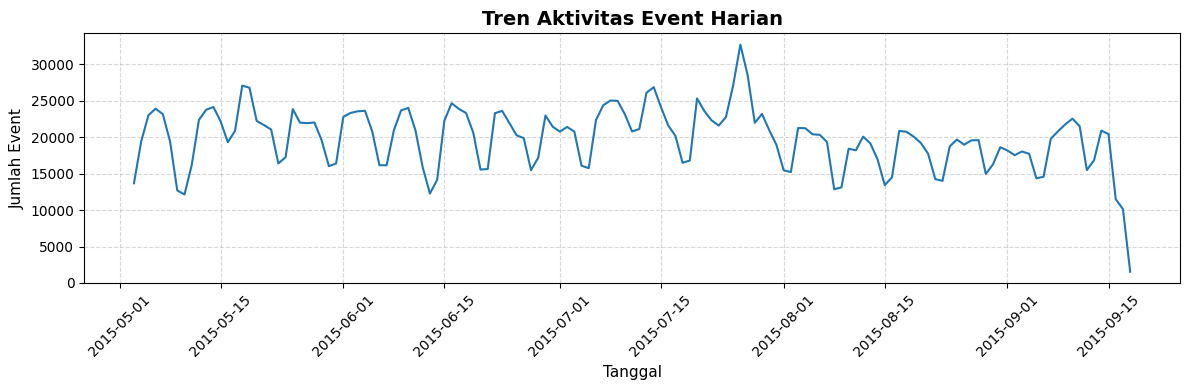

In [16]:
tgl_mulai = df_retailrocket["datetime"].min()
tgl_selesai = df_retailrocket["datetime"].max()

print(f"Tanggal Awal   : {tgl_mulai}")
print(f"Tanggal Akhir  : {tgl_selesai}")
print(f"Total Durasi   : {tgl_selesai - tgl_mulai}")

df_retailrocket["date"] = df_retailrocket["datetime"].dt.date
daily_events = df_retailrocket.groupby("date").size()

plt.figure(figsize=(12, 4))
plt.plot(
    daily_events.index,
    daily_events.values,
    color="#1f77b4",
    linewidth=1.5,
    label="Total Event",
)

plt.title("Tren Aktivitas Event Harian", fontsize=14, fontweight="bold")
plt.xlabel("Tanggal", fontsize=11)
plt.ylabel("Jumlah Event", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 2.1.2 Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!
Proses yang dilakukan pada tahap ini berupa:
- Membagi DataFrame `df` menjadi dua subset berdasarkan rentang tanggal (`p1_start–p1_end` untuk training, `p2_start–p2_end` untuk testing).
- Menghapus kolom datetime dari kedua DataFrame (`df_p1` dan `df_p2`).
- Menghapus baris data yang identik menggunakan `.drop_duplicates()` serta menghitung jumlah baris duplikat yang terbuang.
- Menyimpan hasil akhir data training ke `data/events_p1.csv` dan data testing ke `data/events_p2.csv`.

In [17]:
df_p1 = df_retailrocket[(df_retailrocket["datetime"] >= p1_start) & (df_retailrocket["datetime"] <= p1_end)].copy()
df_p2 = df_retailrocket[(df_retailrocket["datetime"] >= p2_start) & (df_retailrocket["datetime"] <= p2_end)].copy()

df_p1 = df_p1.drop(columns=["datetime"])
df_p2 = df_p2.drop(columns=["datetime"])

rows_p1_before = len(df_p1)
rows_p2_before = len(df_p2)

df_p1 = df_p1.drop_duplicates()
df_p2 = df_p2.drop_duplicates()

p1_duplicates = rows_p1_before - len(df_p1)
p2_duplicates = rows_p2_before - len(df_p2)

print(f"\nJumlah baris total awal           : {len(df_retailrocket)}")
print(
    f"Jumlah baris Periode P1 (Training): {len(df_p1)} (Dihapus {p1_duplicates} duplikat)"
)
print(
    f"Jumlah baris Periode P2 (Testing) : {len(df_p2)} (Dihapus {p2_duplicates} duplikat)"
)

df_p1.to_csv("data_filtered/events_p1.csv", index=False)
df_p2.to_csv("data_filtered/events_p2.csv", index=False)

print("\nFile berhasil disimpan secara terpisah:")
print(" -> Data Training (P1): 'data_filtered/events_p1.csv'")
print(" -> Data Testing  (P2): 'data_filtered/events_p2.csv'")


Jumlah baris total awal           : 2756101
Jumlah baris Periode P1 (Training): 1009164 (Dihapus 125 duplikat)
Jumlah baris Periode P2 (Testing) : 292404 (Dihapus 47 duplikat)

File berhasil disimpan secara terpisah:
 -> Data Training (P1): 'data_filtered/events_p1.csv'
 -> Data Testing  (P2): 'data_filtered/events_p2.csv'


Setelah mendapatkan file P1 dan P2, maka dilanjutkan untuk memasukkan data pada `events_p1.csv` ke dalam database `neo4j` menggunakan kode pada nomor 1.3.

In [23]:
with open(FILE_PATH, "r", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows // BATCH_SIZE) + (
    1 if total_rows % BATCH_SIZE != 0 else 0
)

chunks = pd.read_csv(FILE_PATH, chunksize=BATCH_SIZE)

with driver.session(database=DATABASE) as session:
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(
            lambda tx, batch: tx.run(cypher_query, batch=batch), records
        )

print("Proses impor data ke Neo4j selesai")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=6, column=1, offset=118>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 118, 'line': 6, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nUNWIND $batch AS row\nMERGE (v:Visitor {visitorId: row.visitorid})\nMERGE (i:Item {itemId: row.itemid})\nWITH v, i, row\nCALL {\n    WITH v, i, row\n    WITH v, i, row WHERE row.event = 'view'\n    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n    UNION ALL\n    WITH v, i, row\n    WITH v, i, row WHERE row.event = 'addtoca

Proses impor data ke Neo4j selesai


### 2.1.3 Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat.
Pada tahap ini dilakukan penerapan eksekusi kueri Cypher menggunakan Python API (neo4j driver) dan pandas untuk menampilkan data komposisi simpul (nodes).

In [24]:
query_nodes = """
MATCH (n)
RETURN labels(n)[0] AS Label, count(n) AS Jumlah
ORDER BY Jumlah DESC
"""

query_rels = """
MATCH ()-[r]->()
RETURN type(r) AS JenisRelasi, count(r) AS Jumlah
ORDER BY Jumlah DESC
"""

with driver.session(database=DATABASE) as session:
    res_nodes = session.run(query_nodes)
    df_nodes = pd.DataFrame([rec.data() for rec in res_nodes])
    
    res_rels = session.run(query_rels)
    df_rels = pd.DataFrame([rec.data() for rec in res_rels])

print("=== KOMPOSISI SIMPUL (NODES) ===")
print(df_nodes)

print("\n=== KOMPOSISI RELASI (RELATIONSHIPS) ===")
print(df_rels)

=== KOMPOSISI SIMPUL (NODES) ===
     Label  Jumlah
0  Visitor  514568
1     Item  150807

=== KOMPOSISI RELASI (RELATIONSHIPS) ===
     JenisRelasi  Jumlah
0         VIEWED  976774
1  ADDED_TO_CART   24306
2         BOUGHT    8084


Penjelasan CYPHER SQL yang digunakan pada tahap ini adalah:
| Query CYPHER SQL | Penjelasan |
| :--- | :--- |
| `MATCH (n)`| Mencari dan mengidentifikasi seluruh simpul (node) yang tersimpan di dalam database graf. Tanda kurung () merepresentasikan simpul, dan n adalah variabel penampung untuk setiap simpul yang ditemukan. |
| `MATCH ()-[r]->()` | Mencari seluruh pola hubungan berarah dari satu simpul ke simpul lainnya di dalam graf. Tanda `()-[r]->()` mencocokkan sembarang simpul asal dan tujuan tanpa membatasi labelnya, sedangkan variabel `r` digunakan untuk menampung setiap relasi yang ditemukan. |
| `labels(n)[0] AS Label` | Fungsi `labels(n)` mengembalikan daftar (list) label yang dimiliki oleh simpul `n`. Indeks `[0]` digunakan untuk mengambil nama label utama (elemen pertama), yang kemudian diberi nama alias kolom `Label`. |
| `type(r) AS JenisRelasi` | Fungsi `type(r)` mengambil nama atau tipe string dari relasi `r` (seperti `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`), kemudian diberi nama alias kolom `JenisRelasi`. |
| `count(n)/count(r) AS Jumlah` | Fungsi agregasi untuk menghitung akumulasi kemunculan jumlah simpul `n`/`r` berdasarkan pengelompokan labelnya. Hasil hitungan diberi nama alias kolom `Jumlah`. |
| `ORDER BY Jumlah DESC` | Mengurutkan baris hasil keluaran berdasarkan kolom `Jumlah` secara menurun (descending), sehingga label dengan entitas terbanyak muncul di baris paling atas. |

#### Persiapan Data & Matriks Bipartit

In [35]:
query_user_item = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, count(r) AS weight
"""

with driver.session(database=DATABASE) as session:
    res = session.run(query_user_item)
    df_edges = pd.DataFrame([rec.data() for rec in res])

user_cat = pd.Categorical(df_edges['visitor'])
item_cat = pd.Categorical(df_edges['item'])

row_ind = user_cat.codes
col_ind = item_cat.codes
data = df_edges['weight'].values

n_users = len(user_cat.categories)
n_items = len(item_cat.categories)

M = sp.csr_matrix((data, (row_ind, col_ind)), shape=(n_users, n_items))

print(f"Matriks Bipartit M berhasil dibuat!")
print(f"Total Visitor Unique (|U|) : {n_users:,}")
print(f"Total Item Unique (|I|)    : {n_items:,}")

Matriks Bipartit M berhasil dibuat!
Total Visitor Unique (|U|) : 514,568
Total Item Unique (|I|)    : 150,807


### 2.1.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User.

=== KARAKTERISTIK PROYEKSI USER ===
1. Shape Matriks Proyeksi User : (514568, 514568) (Matriks |U| x |U|)
2. Dimensi Matriks             : 2D
3. Total Simpul User (|U|)     : 514,568
4. Total Relasi Terbentuk      : 14,262,502
5. Densitas Graf User          : 0.000108


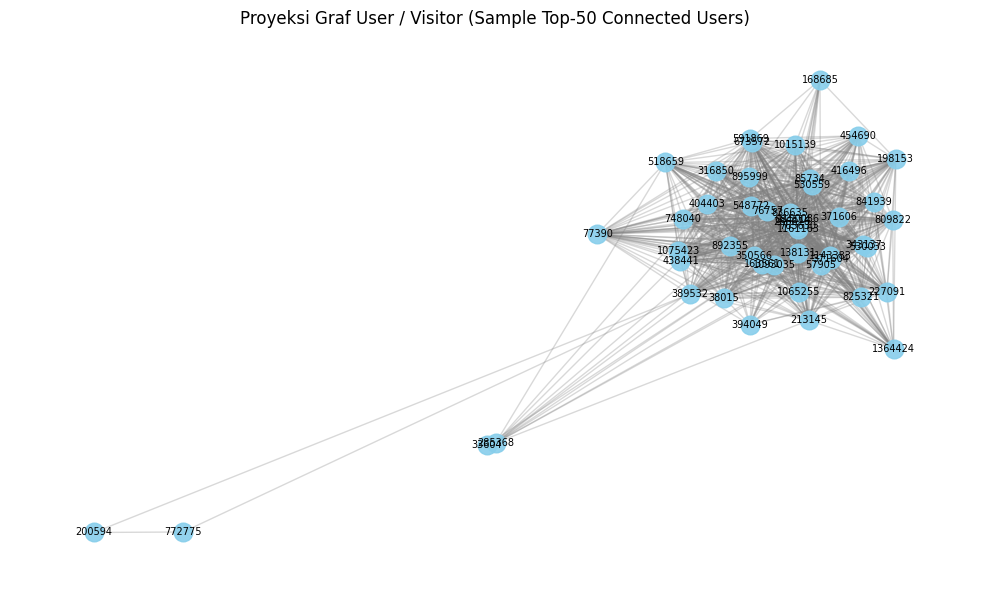

In [36]:
# Proyeksi User: A_user = M * M^T
A_user = M.dot(M.T)
A_user.setdiag(0)

# Ekstraksi Karakteristik User
shape_val_user = A_user.shape
dim_val_user = 2
total_users = shape_val_user[0]
total_edges_user = A_user.nnz // 2
density_user = (2 * total_edges_user) / (total_users * (total_users - 1)) if total_users > 1 else 0

print("=== KARAKTERISTIK PROYEKSI USER ===")
print(f"1. Shape Matriks Proyeksi User : {shape_val_user} (Matriks |U| x |U|)")
print(f"2. Dimensi Matriks             : {dim_val_user}D")
print(f"3. Total Simpul User (|U|)     : {total_users:,}")
print(f"4. Total Relasi Terbentuk      : {total_edges_user:,}")
print(f"5. Densitas Graf User          : {density_user:.6f}")

user_degrees = np.array(A_user.sum(axis=1)).flatten()
top50_user_idx = np.argsort(user_degrees)[-50:]

sub_A_user = A_user[top50_user_idx, :][:, top50_user_idx].toarray()
top50_user_labels = user_cat.categories[top50_user_idx]

G_user = nx.from_numpy_array(sub_A_user)
G_user = nx.relabel_nodes(G_user, dict(enumerate(top50_user_labels)))

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_user, k=0.15, seed=42)
nx.draw_networkx_nodes(G_user, pos, node_size=180, node_color='skyblue', alpha=0.9)
nx.draw_networkx_edges(G_user, pos, alpha=0.3, edge_color='gray')
nx.draw_networkx_labels(G_user, pos, font_size=7, font_family='sans-serif')

plt.title("Proyeksi Graf User / Visitor (Sample Top-50 Connected Users)", fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()

Memiliki nilai densitas $0,000108$ ($0,0108\%$). Nilai ini menunjukkan bahwa graf bersifat extremely sparse (sangat renggang), di mana mayoritas pasangan pengguna tidak memiliki riwayat interaksi item yang bersirisan. Fragmentasi strukturnya juga tinggi karena pada plot terlihat memiliki tingkatan kluster berhirarki dari kluster pusat, kluster perantara, hingga outlier yang jauh.

### 2.1.5 Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. 

=== KARAKTERISTIK PROYEKSI ITEM ===
1. Shape Matriks Proyeksi Item : (150807, 150807) (Matriks |I| x |I|)
2. Dimensi Matriks             : 2D
3. Total Simpul Item (|I|)     : 150,807
4. Total Relasi Terbentuk      : 7,391,197
5. Densitas Graf Item          : 0.000650


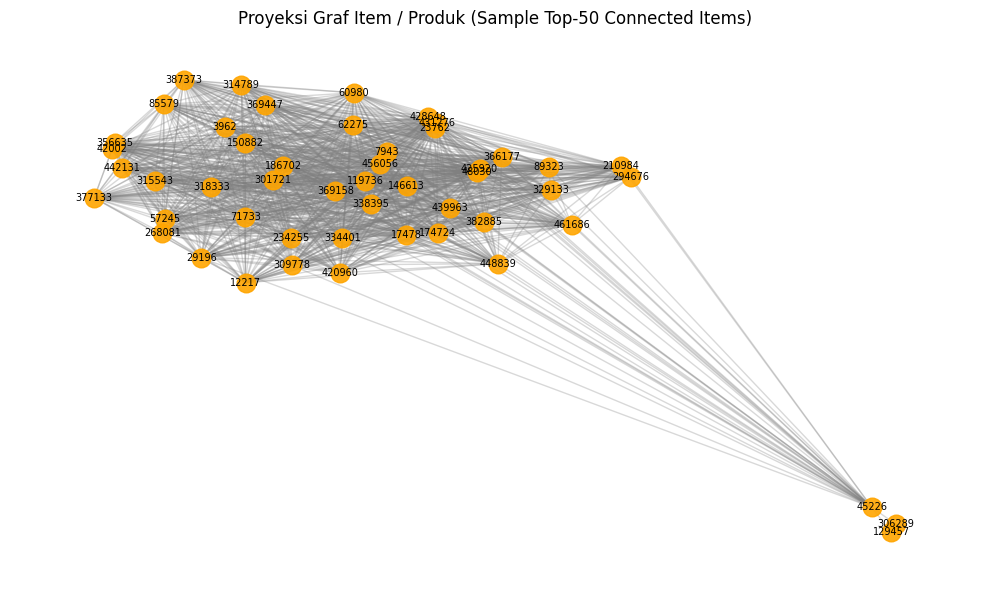

In [37]:
# Proyeksi Item: A_item = M^T * M
A_item = M.T.dot(M)
A_item.setdiag(0)
A_item.eliminate_zeros()

# Ekstraksi Karakteristik Item
shape_val_item = A_item.shape
dim_val_item = 2
total_items = shape_val_item[0]
total_edges_item = A_item.nnz // 2
density_item = (2 * total_edges_item) / (total_items * (total_items - 1)) if total_items > 1 else 0

print("=== KARAKTERISTIK PROYEKSI ITEM ===")
print(f"1. Shape Matriks Proyeksi Item : {shape_val_item} (Matriks |I| x |I|)")
print(f"2. Dimensi Matriks             : {dim_val_item}D")
print(f"3. Total Simpul Item (|I|)     : {total_items:,}")
print(f"4. Total Relasi Terbentuk      : {total_edges_item:,}")
print(f"5. Densitas Graf Item          : {density_item:.6f}")

item_degrees = np.array(A_item.sum(axis=1)).flatten()
top50_item_idx = np.argsort(item_degrees)[-50:]

sub_A_item = A_item[top50_item_idx, :][:, top50_item_idx].toarray()
top50_item_labels = item_cat.categories[top50_item_idx]

G_item = nx.from_numpy_array(sub_A_item)
G_item = nx.relabel_nodes(G_item, dict(enumerate(top50_item_labels)))

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_item, k=0.15, seed=42)
nx.draw_networkx_nodes(G_item, pos, node_size=180, node_color='orange', alpha=0.9)
nx.draw_networkx_edges(G_item, pos, alpha=0.3, edge_color='gray')
nx.draw_networkx_labels(G_item, pos, font_size=7, font_family='sans-serif')

plt.title("Proyeksi Graf Item / Produk (Sample Top-50 Connected Items)", fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()

Memiliki nilai densitas $0,000650$ ($0,0650\%$). Nilai ini menunjukkan bahwa graf item juga bersifat sparse, tetapi tingkat kerapatan antarsimpulnya sekitar 6 kali lipat lebih rapat dibandingkan proyeksi User. Fragmentasi strukturnya juga rendah karena pada plot terlihat memiliki struktur cenderung menyatu homogen dalam satu blok besar.

### 2.1.6 eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Dari eksplorasi no. 4 dan 5, saya mendapatkan karakteristik untuk masing-masing proyeksi User dan Item. Dari hasil tersebut diketahui:

#### Efisiensi (User vs Item)

* **Shape Matrix:** $(514568, 514568)$ vs $(150807, 150807)$
  * Menunjukkan bahwa proyeksi Item lebih kecil sehingga alokasi ruang memori matriks Item jauh lebih kecil.
* **Relasi Terbentuk:** $14,262,502$ vs $7,391,197$
  * Menunjukkan bahwa proyeksi Item lebih kecil sehingga perhitungan similarity $2\times$ lebih cepat karena relasi yang diproses jauh lebih sedikit.

#### Efektivitas (User vs Item)

* **Densitas:** $0.000108$ vs $0.000650$
  * Menunjukkan bahwa proyeksi Item lebih besar sehingga lebih padat serta hubungan antar-item lebih stabil dan kaya informasi.
* **Plot:** Struktur Komunitas vs Dense Core Terpusat
  * Menunjukkan bahwa proyeksi Item memiliki hubungan asosiasi antar-produk yang kuat dan permanen.

Jadi dari kesimpulan tersebut dapat diketahui bahwa **proyeksi Item memiliki performa yang lebih baik**.

### 2.1.7 Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python

(a) Tuliskan CYPHERSQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

Proses yang dilakukan pada tahap ini berupa:
- Menghitung total interaksi unik pengguna untuk setiap item, lalu memilih item dengan jumlah interaksi terbanyak (item paling populer) sebagai acuan.
- Menghitung norma L2 ($\sqrt{\text{jumlah user}}$) untuk setiap item sebagai penyebut dalam rumus normalisasi Cosine Similarity.
- Mengambil nilai perkalian titik (dot product) dari matriks $A_{item}$ yang merepresentasikan jumlah pengguna yang sama antara item target dengan seluruh item lainnya.
- Menghitung skor kemiripan menggunakan rumus $\frac{\text{Irisan}}{\text{Norma Target} \times \text{Norma Item}}$ secara tervektorisasi, lengkap dengan penanganan pembagian nol.
- Mengubah skor kemiripan item target terhadap dirinya sendiri menjadi 0 agar tidak muncul dalam rekomendasi.
- Mengurutkan skor kemiripan secara menurun (descending) dan mengambil 5 indeks item dengan nilai kemiripan tertinggi.

In [49]:
item_user_count = np.array(M.getnnz(axis=0)).flatten()
item_norms = np.sqrt(item_user_count)

target_idx = np.argmax(item_user_count)
target_item_id = item_cat.categories[target_idx]

intersection_vector = A_item.getcol(target_idx).toarray().flatten()

norm_product = item_norms[target_idx] * item_norms
cosine_scores = np.divide(
    intersection_vector, 
    norm_product, 
    out=np.zeros_like(intersection_vector, dtype=float), 
    where=norm_product != 0
)

cosine_scores[target_idx] = 0

top5_indices = np.argsort(cosine_scores)[-5:][::-1]

df_top5 = pd.DataFrame({
    'Target_Item': target_item_id,
    'Similar_Item': item_cat.categories[top5_indices],
    'Score': cosine_scores[top5_indices]
})

similar_items_list = df_top5['Similar_Item'].tolist()
print("=== TOP-5 SIMILAR ITEMS (COSINE SIMILARITY) ===")
print(df_top5)

=== TOP-5 SIMILAR ITEMS (COSINE SIMILARITY) ===
   Target_Item  Similar_Item     Score
0         5411        100445  0.584750
1         5411        329643  0.309936
2         5411         33030  0.262983
3         5411        282419  0.247565
4         5411        258598  0.243104


(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

In [41]:
target_ids = list(set([int(row['Target_Item']) for _, row in df_top5.iterrows()]))

query_delete_old = """
MATCH (i1:Item)-[r:SIMILAR]->()
WHERE i1.itemId IN $target_ids
DELETE r
"""

query_writeback = """
UNWIND $data AS row
MATCH (i1:Item {itemId: row.target})
MATCH (i2:Item {itemId: row.similar})
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = row.score
"""

payload = [
    {
        "target": int(row['Target_Item']),
        "similar": int(row['Similar_Item']),
        "score": float(row['Score'])
    }
    for _, row in df_top5.iterrows()
]

with driver.session(database=DATABASE) as session:
    session.run(query_delete_old, target_ids=target_ids)
    session.run(query_writeback, data=payload)

print("\nRelasi :SIMILAR lama berhasil dibersihkan dan relasi baru berhasil ditulis!")


Relasi :SIMILAR lama berhasil dibersihkan dan relasi baru berhasil ditulis!


### 2.1.8 Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [50]:
target_item = 5411
top5_similar_ids = similar_items_list

query_before = """
MATCH (i1:Item {itemId: $target_id})<-[r1]-(v:Visitor)-[r2]->(i2:Item)
WHERE i2.itemId IN $similar_ids
RETURN v.visitorId AS visitor, i1.itemId AS target, i2.itemId AS similar
LIMIT 40
"""

query_after = """
MATCH (i:Item {itemId: $item_id})-[r:SIMILAR]->(sim:Item)
RETURN i.itemId AS target, sim.itemId AS similar, r.score AS score
"""

with driver.session(database=DATABASE) as session:
    res = session.run(query_before, target_id=target_item, similar_ids=top5_similar_ids)
    data_before = [rec.data() for rec in res]
    
with driver.session(database=DATABASE) as session:
    res_after = session.run(query_after, item_id=target_item)
    edges_after = [(f"Item_{rec['target']}", f"Item_{rec['similar']}", round(rec['score'], 3)) for rec in res_after]

Before (Graf Bipartit Awal)

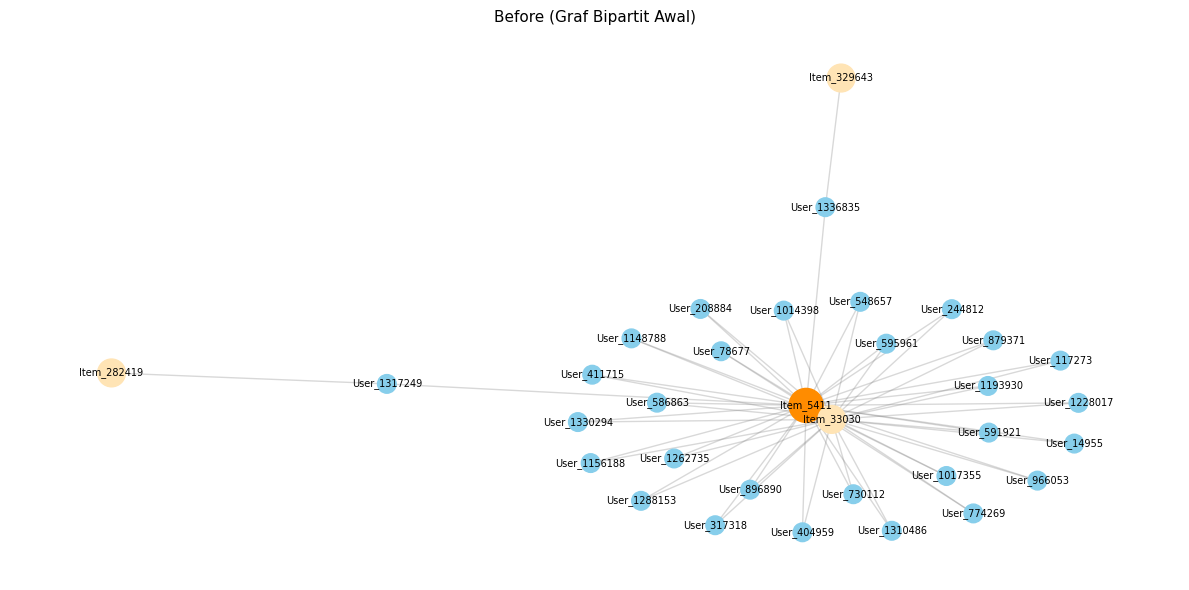

In [51]:
G_before = nx.Graph()

for row in data_before:
    v_node = f"User_{row['visitor']}"
    t_node = f"Item_{row['target']}"
    s_node = f"Item_{row['similar']}"
    
    G_before.add_edge(v_node, t_node)
    G_before.add_edge(v_node, s_node)

node_colors = []
node_sizes = []

for node in G_before.nodes():
    if str(target_item) in node:
        node_colors.append('darkorange')
        node_sizes.append(600)
    elif 'Item' in node:
        node_colors.append('moccasin')
        node_sizes.append(400)
    else:
        node_colors.append('skyblue')
        node_sizes.append(180)

plt.figure(figsize=(12, 6))
pos_before = nx.spring_layout(G_before, seed=42, k=0.3)

nx.draw_networkx_nodes(G_before, pos_before, node_color=node_colors, node_size=node_sizes)
nx.draw_networkx_edges(G_before, pos_before, alpha=0.3, edge_color='gray')
nx.draw_networkx_labels(G_before, pos_before, font_size=7)

plt.title(f"Before (Graf Bipartit Awal)", fontsize=11)
plt.axis('off')
plt.tight_layout()
plt.show()

After (Proyeksi Relasi :SIMILAR)

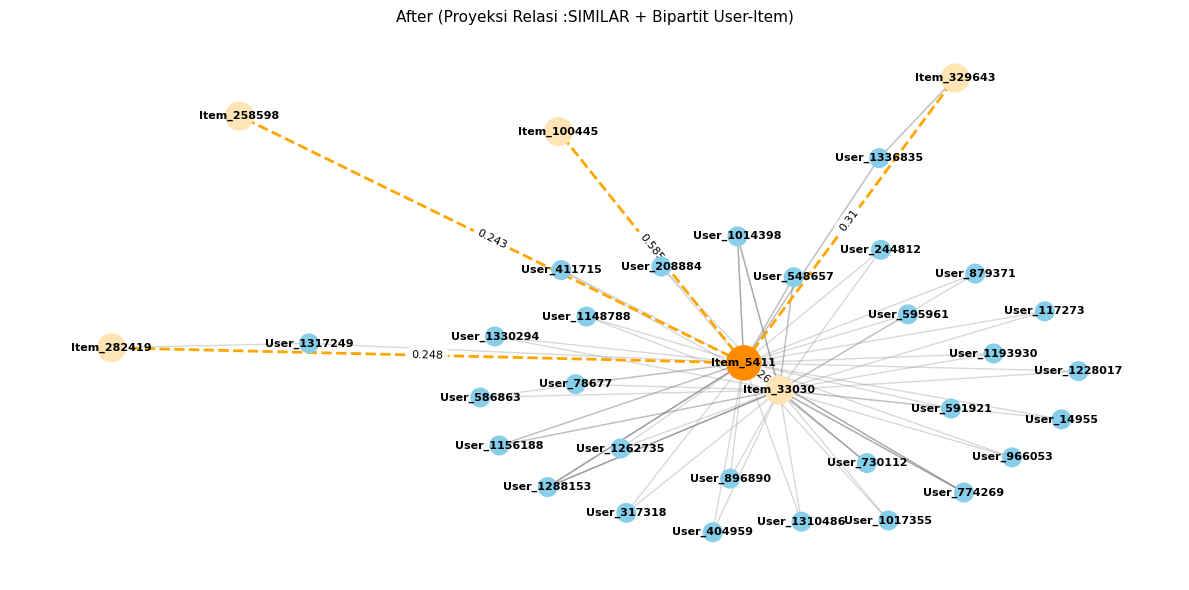

In [54]:
G_after = nx.Graph()

bipartite_edges = []
for row in data_before:
  v_node = f"User_{row['visitor']}"
  t_node = f"Item_{row['target']}"
  s_node = f"Item_{row['similar']}"

  G_after.add_edge(v_node, t_node)
  G_after.add_edge(v_node, s_node)
  bipartite_edges.extend([(v_node, t_node), (v_node, s_node)])

similar_edges = []
similar_labels = {}
for src, dst, w in edges_after:
  G_after.add_edge(src, dst, weight=w)
  similar_edges.append((src, dst))
  similar_labels[(src, dst)] = str(w)

plt.figure(figsize=(12, 6))
pos_after = nx.spring_layout(G_after, seed=42, k=0.35)

node_colors_after = []
node_sizes_after = []
for node in G_after.nodes():
  if str(target_item) in node:
    node_colors_after.append("darkorange")
    node_sizes_after.append(600)
  elif "Item" in node:
    node_colors_after.append("moccasin")
    node_sizes_after.append(400)
  else:
    node_colors_after.append("skyblue")
    node_sizes_after.append(180)

nx.draw_networkx_nodes(
    G_after, pos_after, node_color=node_colors_after, node_size=node_sizes_after
)

nx.draw_networkx_edges(
    G_after,
    pos_after,
    edgelist=bipartite_edges,
    alpha=0.3,
    edge_color="gray",
    style="solid",
)
nx.draw_networkx_edges(
    G_after,
    pos_after,
    edgelist=similar_edges,
    width=2,
    edge_color="orange",
    style="dashed",
)

nx.draw_networkx_labels(G_after, pos_after, font_size=8, font_weight="bold")
nx.draw_networkx_edge_labels(
    G_after, pos_after, edge_labels=similar_labels, font_size=8
)

plt.title(
    f"After (Proyeksi Relasi :SIMILAR + Bipartit User-Item)", fontsize=11
)
plt.axis("off")
plt.tight_layout()
plt.show()

Pada graf Before, hubungan antar-item masih bersifat tidak langsung karena terpisah oleh simpul-simpul User dalam struktur graf bipartit. Setelah perhitungan similarity pada graf After, hubungan antara item acuan `5411` dan kelima item lain tidak lagi melalui user, melainkan menjadi relasi langsung `:SIMILAR` yang membawa skor cosine. Item `100445` paling mirip (0,585), diikuti `329643` (0,31), `33030` (0,26), `282419` (0,248), dan `258598` (0,243). Nilai skor yang terbentang hingga 0,585 menunjukkan adanya irisan interaksi pengguna yang cukup kuat pada item-item terkait dengan item acuan. Graf yang semula User-Item bertransformasi menjadi graf Item-Item berbobot yang dapat dipakai langsung untuk mencari tetangga terdekat (KNN) pada tahap rekomendasi.

## 2. Soal UTS  |  2.2 Analytics

### 2.2.1 Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu:
Untuk pemilihan sampel user digunakan kriteria berikut:
- Mengambil pengguna yang muncul di kedua periode (`P1` dan `P2`).
- Memastikan pengguna memiliki setidaknya 5 interaksi item di masa lalu agar model rekomendasi memiliki informasi yang cukup (warm-start).
- Memastikan pengguna memiliki minimal 1 interaksi aktual di P2 agar evaluasi metrik (Precision, Recall, NDCG) tidak menghasilkan nilai nol/pembagian nol akibat ground truth kosong.
- Mengambil 100 sampel pengguna secara acak dari daftar kandidat yang lolos filter menggunakan `random_state=42`.

In [60]:
df_p1 = pd.read_csv("data_filtered/events_p1.csv")
df_p2 = pd.read_csv("data_filtered/events_p2.csv")

user_col = "visitorid" if "visitorid" in df_p1.columns else "visitor"
item_col = "itemid" if "itemid" in df_p1.columns else "item"

p1_item_counts = df_p1.groupby(user_col)[item_col].nunique()
p2_item_counts = df_p2.groupby(user_col)[item_col].nunique()

valid_p1_users = set(p1_item_counts[p1_item_counts >= 5].index)
valid_p2_users = set(p2_item_counts[p2_item_counts >= 1].index)

candidate_users = sorted(list(valid_p1_users.intersection(valid_p2_users)))

np.random.seed(SEED)

df_candidates = pd.Series(candidate_users)
sample_test_users = df_candidates.sample(
    n=min(100, len(df_candidates)), random_state=SEED
).tolist()

target_user_id = sample_test_users[0]

df_p2_overlap = df_p2[df_p2[user_col].isin(sample_test_users)]
ground_truth_p2 = (
    df_p2_overlap.groupby(user_col)[item_col].unique().apply(list).to_dict()
)

print(
    f"Total kandidat user yang memenuhi kriteria : {len(candidate_users):,}"
)
print(f"Total sampel user terambil             : {len(sample_test_users)}")
print(
    f"Target User Terpilih (Terkunci)        : {target_user_id}"
)

Total kandidat user yang memenuhi kriteria : 1,431
Total sampel user terambil             : 100
Target User Terpilih (Terkunci)        : 142299


(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!<br>
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [62]:
item_user_count = np.array(M.getnnz(axis=0)).flatten()
item_norms = np.sqrt(item_user_count)

inv_norms = np.zeros_like(item_norms, dtype=float)
mask = item_norms > 0
inv_norms[mask] = 1.0 / item_norms[mask]

D_inv = sp.diags(inv_norms)
S_item = D_inv.dot(A_item).dot(D_inv).tocsr()

S_item.setdiag(0)
S_item.eliminate_zeros()

user_ids = list(user_cat.categories)
user_idx = user_ids.index(target_user_id)

user_profile = M[user_idx, :]
visited_indices = (
    user_profile.indices
)

scores = user_profile.dot(S_item).toarray().flatten()
scores[visited_indices] = 0
top_k_indices = np.argsort(scores)[-k:][::-1]

df_recommendations = pd.DataFrame({
    "Target_User": target_user_id,
    "Recommended_Item": [item_cat.categories[i] for i in top_k_indices],
    "Score": scores[top_k_indices],
})

print(f"=== REKOMENDASI ITEM-BASED KNN UNTUK USER: {target_user_id} ===")
print(df_recommendations)

print("\n=== 3 ITEM TERATAS UNTUK DIIKLANKAN ===")
print(df_recommendations.head(3))

=== REKOMENDASI ITEM-BASED KNN UNTUK USER: 142299 ===
   Target_User  Recommended_Item     Score
0       142299            460241  2.121320
1       142299            158188  1.500000
2       142299             83840  1.060660
3       142299            166206  0.948683
4       142299            129529  0.866025

=== 3 ITEM TERATAS UNTUK DIIKLANKAN ===
   Target_User  Recommended_Item    Score
0       142299            460241  2.12132
1       142299            158188  1.50000
2       142299             83840  1.06066


Berdasarkan hasil pada soal nomor 2.1.6, diketahui bahwa `Proyeksi Item` lebih efektif dan efisien, sehingga diputuskan untuk menggunakan metode `Item-Based KNN`.

Dari hasil KNN, terpilih 5 produk tertinggi untuk dijadikan rekomendasi bagi Pengguna `142299`, yaitu item `460241` (skor: 2,1213), `158188` (1,5000), `83840` (1,0607), `166206` (0,9487), dan `129529` (0,8660).<br>
Dari kelima kandidat tersebut, 3 produk teratas (`460241`, `158188`, dan `83840`) dipilih sebagai prioritas utama untuk ditayangkan dalam kampanye iklan personal (targeted display ads). Strategi ini bertujuan untuk memaksimalkan Click-Through Rate (CTR) serta memicu konversi transaksi pada periode berikutnya (P2).

### 2.2.2 Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah Hit@5 dan NDCG@5
Dari hasil yang didapat dari KNN tadi, akan dihitung:
- `Hit@5`: Mengukur apakah minimal ada 1 item rekomendasi dari daftar Top-5 yang benar-benar diakses/dibeli pengguna pada periode P2 (ground truth). Bernilai 1 jika ada minimal 1 tebakan benar, dan 0 jika tidak ada sama sekali.
- `NDCG@5` (Normalized Discounted Cumulative Gain): Mengukur kualitas dan presisi posisi dari rekomendasi yang tepat. Item relevan yang berada di peringkat atas (posisi 1–2) memberikan skor yang jauh lebih tinggi daripada item relevan di peringkat bawah (posisi 4–5) menggunakan bobot diskon logaritma: $\frac{1}{\log_2(\text{posisi} + 1)}$.

In [66]:
recommended_items = df_recommendations["Recommended_Item"].head(5).tolist()
actual_items = ground_truth_p2.get(target_user_id, [])

# Binary Relevance
hits = [1 if item in actual_items else 0 for item in recommended_items]

# Kalkulasi Hit@5
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

# Kalkulasi DCG@5
dcg_at_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(hits)])

# Kalkulasi IDCG@5
ideal_hits = [1] * min(len(actual_items), 5)
idcg_at_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(ideal_hits)])

# NDCG@5
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

print(f"=== EVALUASI METRIK USER: {target_user_id} ===")
print(f"Ground Truth P2 (Actual) : {actual_items}")
print(f"Top-5 Rekomendasi (KNN)  : {recommended_items}")
print(f"Irisan Matched (Hits)    : {hits}")
print(f"Hit@5                    : {hit_at_5}")
print(f"NDCG@5                   : {ndcg_at_5:.4f}")

=== EVALUASI METRIK USER: 142299 ===
Ground Truth P2 (Actual) : [np.int64(172774)]
Top-5 Rekomendasi (KNN)  : [460241, 158188, 83840, 166206, 129529]
Irisan Matched (Hits)    : [0, 0, 0, 0, 0]
Hit@5                    : 0.0
NDCG@5                   : 0.0000


Hasil Hit@5 dan NDCG@5 bernilai 0 karena tidak satupun rekomendasi terdapat pada Ground Truth. Hal tersebut terjadi pada Pengguna `142299` akibat tingginya kelangkaan data (extreme sparsity) dan bias model Item-Based KNN terhadap kelompok produk populer di dense core, sehingga gagal merekomendasikan item aktual P2 (`172774`) yang bersifat long-tail. Dinamika preferensi pengguna yang terfragmentasi serta ground truth P2 yang hanya berjumlah satu item menciptakan sparsity bottleneck pada pengujian skala individu, yang menegaskan perlunya mengevaluasi performa model berdasarkan rata-rata agregat (Mean Hit@5 dan Mean NDCG@5) di seluruh sampel pengguna.